# Project: Analyzing Chicago City Employee Salaries

This is the capstone of the repository. Instead of teaching one method at a time, we combine everything from the earlier notebooks to answer **real questions** about a **real, messy dataset**: the City of Chicago's public employee salary records (about 32,000 employees).

You'll practice the exact workflow used by working analysts:
1. **Load** data and inspect its shape and types.
2. **Clean** it — the salary column is text (`$90744.00`), and there are missing values.
3. **Explore** with `groupby`, sorting, and filtering.
4. **Visualize** the findings.
5. **Summarize** the answers in plain English.

This is public data (City of Chicago open data), included in the repo so everything is reproducible offline.

## Step 0: Load and inspect

Always start the same way: `head()`, `info()`, `describe()`. The first problem is visible immediately — the salary column is `object` (text), not a number.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

salaries = pd.read_csv("chicago.csv")
salaries.head()

,Name,Position Title,Department,Employee Annual Salary
0,"AARON, ELVIA J",WATER RATE TAKER,WATER MGMNT,$90744.00
1,"AARON, JEFFERY M",POLICE OFFICER,POLICE,$84450.00
2,"AARON, KARINA",POLICE OFFICER,POLICE,$84450.00
3,"AARON, KIMBERLEI R",CHIEF CONTRACT EXPEDITER,GENERAL SERVICES,$89880.00
4,"ABAD JR, VICENTE M",CIVIL ENGINEER IV,WATER MGMNT,$106836.00


In [2]:
salaries.info()

<class 'pandas.DataFrame'>
RangeIndex: 32063 entries, 0 to 32062
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Name                    32062 non-null  str  
 1   Position Title          32062 non-null  str  
 2   Department              32062 non-null  str  
 3   Employee Annual Salary  32062 non-null  str  
dtypes: str(4)
memory usage: 1002.1 KB


## Step 1: Clean the salary column

We cannot compute averages or compare salaries while they are strings like `$90744.00`. The fix: strip the `$` sign and convert to a float. This is one of the most common real-world tasks in Pandas — data almost never arrives typed correctly.

In [3]:
salaries["Salary"] = salaries["Employee Annual Salary"].str.strip("$").astype(float)
salaries["Salary"].describe()

count     32062.000000
mean      80204.178634
std       25098.329868
min           0.960000
25%       72862.400000
50%       84450.000000
75%       93240.000000
max      300000.000000
Name: Salary, dtype: float64

Notice the transformation is **vectorized** — no `for` loop. The `.str` accessor gives string methods to every cell in a column, and `.astype(float)` converts the whole column at once.

## Step 2: Handle missing values

`info()` showed one missing row. Let's find it and remove it, since one incomplete row could skew our analysis.

In [4]:
salaries.isna().sum()

Name                      1
Position Title            1
Department                1
Employee Annual Salary    1
Salary                    1
dtype: int64

In [5]:
salaries[salaries.isna().any(axis=1)]

,Name,Position Title,Department,Employee Annual Salary,Salary
32062,NaN,NaN,NaN,NaN,NaN


In [6]:
salaries = salaries.dropna()
salaries.isna().sum()

Name                      0
Position Title            0
Department                0
Employee Annual Salary    0
Salary                    0
dtype: int64

## Step 3: Which departments have the highest pay?

Here we use **groupby + aggregate + sort** — the split-apply-combine pattern from the GroupBy notebook.

In [7]:
dept = salaries.groupby("Department")["Salary"].agg(["count", "mean", "median", "max"])
dept.sort_values("mean", ascending=False).head(10)

,count,mean,median,max
Department,,,,
DoIT,102,96727.294118,96066.0,154992.0
BUILDINGS,262,96313.738626,97920.0,157092.0
FIRE,4796,95700.627306,91362.0,202728.0
BUDGET & MGMT,39,91989.230769,89340.0,169992.0
HUMAN RELATIONS,16,91065.750000,89676.0,125004.0
TREASURER,22,90526.227273,88626.0,150000.0
IPRA,82,90064.097561,89880.0,161856.0
MAYOR'S OFFICE,86,87571.499535,74250.0,216210.0
BOARD OF ETHICS,9,86697.333333,81948.0,131688.0


**Interpretation**: mean vs median matters. A department with a high mean but low median probably has a few very high earners. `count` also matters — a 3-person department can't be compared fairly with a 12,000-person one like Police.

## Step 4: Who earns the most, overall and per department?

We find top earners with `nlargest`, then show the highest-paid person in each department using `groupby().max()` (or `.idxmax()` to get their name).

In [8]:
salaries.nlargest(10, "Salary")[["Name", "Position Title", "Department", "Salary"]]

,Name,Position Title,Department,Salary
8184,"EVANS, GINGER S",COMMISSIONER OF AVIATION,AVIATION,300000.0
7954,"EMANUEL, RAHM",MAYOR,MAYOR'S OFFICE,216210.0
25532,"SANTIAGO, JOSE A",FIRE COMMISSIONER,FIRE,202728.0
8924,"FORD II, RICHARD C",FIRST DEPUTY FIRE COMMISSIONER,FIRE,197736.0
8042,"ESCALANTE, JOHN J",FIRST DEPUTY SUPERINTENDENT,POLICE,197724.0
19208,"MITCHELL, EILEEN M",CHIEF OF STAFF,MAYOR'S OFFICE,195000.0
3706,"CALLAHAN, MICHAEL E",DEPUTY FIRE COMMISSIONER,FIRE,187680.0
18556,"MC NICHOLAS, JOHN",DEPUTY FIRE COMMISSIONER,FIRE,187680.0
29466,"VASQUEZ, ANTHONY P",DEPUTY FIRE COMMISSIONER,FIRE,187680.0
13754,"JOHNSON, EDDIE T",CHIEF,POLICE,185364.0


In [9]:
idx = salaries.groupby("Department")["Salary"].idxmax()
salaries.loc[idx, ["Name", "Position Title", "Department", "Salary"]].sort_values("Salary", ascending=False)

,Name,Position Title,Department,Salary
8184,"EVANS, GINGER S",COMMISSIONER OF AVIATION,AVIATION,300000.0
7954,"EMANUEL, RAHM",MAYOR,MAYOR'S OFFICE,216210.0
25532,"SANTIAGO, JOSE A",FIRE COMMISSIONER,FIRE,202728.0
8042,"ESCALANTE, JOHN J",FIRST DEPUTY SUPERINTENDENT,POLICE,197724.0
19672,"MORITA, JULIA Y",COMMISSIONER OF HEALTH,HEALTH,177000.0
23631,"REIFMAN, DAVID",COMMISSIONER OF PLANNING & DEVELOPMENT,COMMUNITY DEVELOPMENT,175020.0
19721,"MORRISON BUTLER, LISA V",COMMISSIONER OF FAMILY AND SUPPORT SERVICES,FAMILY & SUPPORT,175002.0
21933,"PATTON, STEPHEN R",CORPORATION COUNSEL,LAW,173664.0
12571,"HOLT, ALEXANDRA D",BUDGET DIR,BUDGET & MGMT,169992.0
22847,"POWERS, THOMAS H",COMMISSIONER OF WATER MGMT,WATER MGMNT,169512.0


## Step 5: Are police officers the majority? A quick look at composition

Use `value_counts(normalize=True)` to see the share of total employees each department represents.

In [10]:
salaries["Department"].value_counts(normalize=True).head(5).mul(100).round(1).astype(str) + "%" 

Department
POLICE           39.4%
FIRE             15.0%
STREETS & SAN     6.7%
OEMC              6.2%
WATER MGMNT       5.7%
Name: proportion, dtype: str

## Step 6: Visualize the findings

Charts turn tables into arguments. Two quick plots: the salary distribution (histogram) and median pay by department (bar chart).

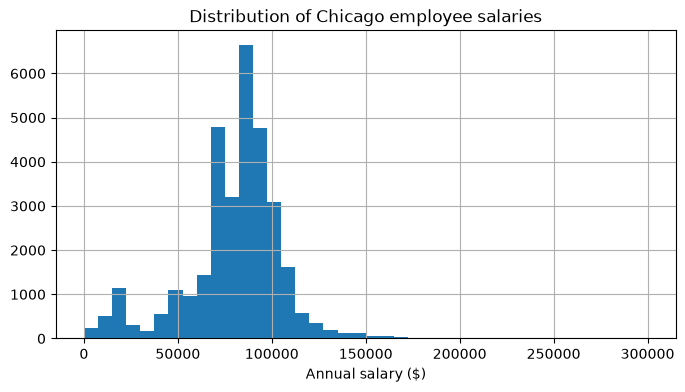

In [11]:
salaries["Salary"].hist(bins=40, figsize=(8, 4))
plt.title("Distribution of Chicago employee salaries")
plt.xlabel("Annual salary ($)")
plt.show()

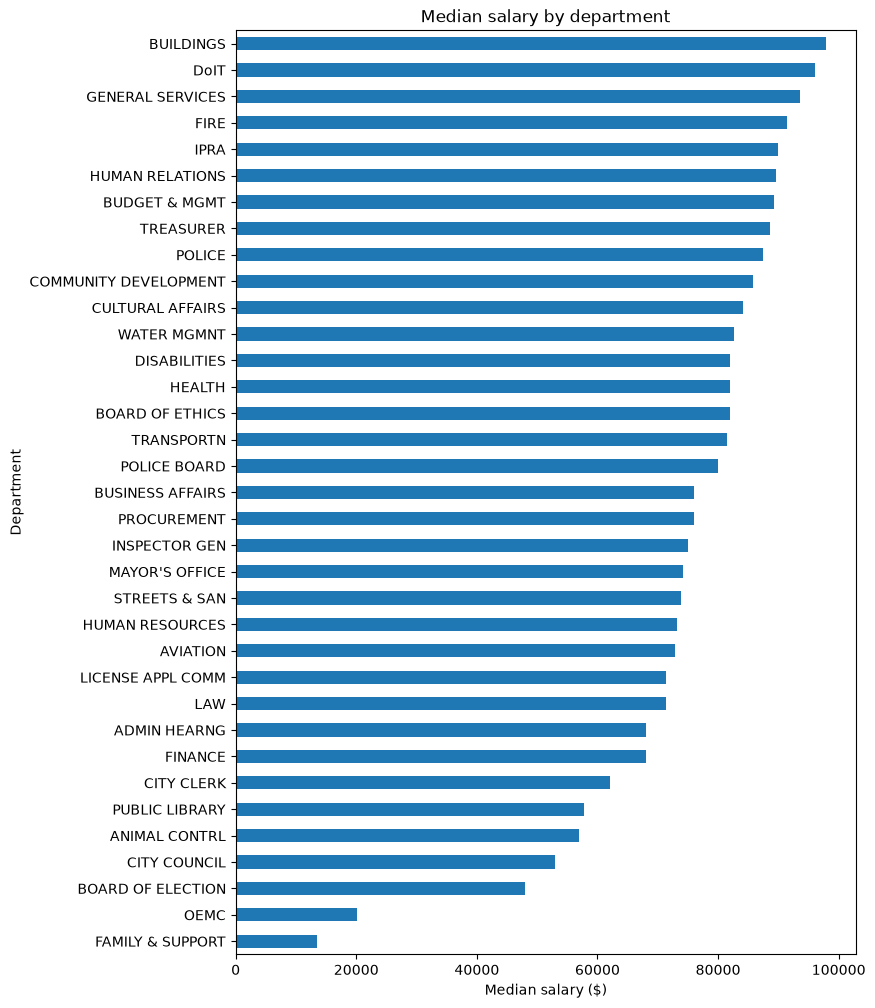

In [12]:
median_by_dept = salaries.groupby("Department")["Salary"].median().sort_values()
median_by_dept.plot(kind="barh", figsize=(8, 12))
plt.title("Median salary by department")
plt.xlabel("Median salary ($)")
plt.show()

## Step 7: Try it yourself

Practice: **which department has the largest gap between its highest- and lowest-paid employee?** (Hint: `groupby` with two aggregations, then subtract.)

A solution is in the next cell — write yours before looking.

In [13]:
# SOLUTION
salaries.groupby("Department")["Salary"].agg(["max", "min"]).assign(range_ = lambda x: x["max"] - x["min"]).sort_values("range_", ascending=False).head(5)

,max,min,range_
Department,,,
AVIATION,300000.0,16395.60,283604.40
MAYOR'S OFFICE,216210.0,0.96,216209.04
POLICE,197724.0,9640.80,188083.20
FAMILY & SUPPORT,175002.0,2756.00,172246.00
FIRE,202728.0,33564.00,169164.00


## What you practiced

- Reading a real CSV and inspecting its types (`info`, `describe`)
- Cleaning a column with `.str` + `astype` (no loops)
- Handling missing data with `dropna`
- `groupby` with multiple aggregations
- `nlargest` and `idxmax` for ranking
- `value_counts` for composition
- Histograms and horizontal bar charts
- Reading results critically (mean vs median vs count)

This is the entire lifecycle of a data analysis task. If any step felt unfamiliar, revisit `06_groupby.ipynb`, `02_dataframes_1.ipynb`, or `10_visualization.ipynb`.

## License

Dataset: City of Chicago open data (public record). Code: MIT, see [LICENSE](./LICENSE).